# 07b · Dimensionamento de mão de obra por turno (nov/2026 – out/2027)
**Pergunta:** quantas pessoas cada turno precisa, mês a mês, no próximo ano, e quanto custa?

Método (em escala cheia):
1. **Previsão de volume por mês**: linhas de separação (por canal e zona) e paletes recebidos.
   Mesmo método da Fase 4: mês do ano anterior × fator de nível (últimos 3 meses / os mesmos 3
   meses um ano antes).
2. **Horas necessárias** = volume × horas por unidade de trabalho (produtividade da 07a).
3. **Pessoas por turno** = horas por noite ÷ (8 h × ocupação planejada × (1 − absenteísmo)).
4. **Quadro fixo × temporários**: o fixo cobre a necessidade dos meses normais; temporários cobrem o pico.

Dois cenários: **método atual** e **método melhorado** (slotting da Fase 5 + lote no e-commerce da 07a).

*EN summary: 12-month forecast of picking lines and received pallets, converted into headcount per
shift and month for current vs improved methods; fixed crew + temporaries plan and labor cost.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flowsim as fs
from dcanalysis import q, save, savefig, log, params, register_saving, ROOT

NB = "07b"
PH7 = ROOT / "reports" / "phase7"
P = params(); prm = fs.carregar_parametros(); slot = fs.carregar_slotting()
LB, CUSTO = P["labor"], P["labor_cost"]
ESCALA = prm["scale"]
NOITES = LB["nights_per_month"] + 4 * P["flow_simulation"]["sunday_shift_share"]   # noites-equivalentes/mês
HORAS_UTEIS = LB["shift_hours"] * LB["utilization_target"] * (1 - LB["absenteeism"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
print(f"Horas produtivas por pessoa por turno: {HORAS_UTEIS:.2f} h | noites-equivalentes/mês: {NOITES}")

Horas produtivas por pessoa por turno: 6.46 h | noites-equivalentes/mês: 27.2


## 1. Previsão de volume (próximos 12 meses)

In [2]:
lin = q("""SELECT substr(f.order_date, 1, 7) AS mes, f.channel, s.zone, COUNT(*) AS linhas
           FROM fact_order_line f JOIN dim_sku s ON s.sku_id = f.sku_id
           WHERE f.order_date >= '2024-11-01' GROUP BY 1, 2, 3""")
pal = q("""SELECT substr(arrival_ts, 1, 7) AS mes, zone, COUNT(*) AS paletes
           FROM fact_receipt WHERE arrival_ts >= '2024-11-01' GROUP BY 1, 2""")
lin = lin.pivot_table(index="mes", columns=["channel", "zone"], values="linhas").fillna(0)
pal = pal.pivot_table(index="mes", columns="zone", values="paletes").fillna(0)

def prever(serie_mensal, meses_futuros=12, janela=3):
    """Mesmo mês do ano anterior x fator de nível (últimos `janela` meses vs. 12 meses antes)."""
    s = serie_mensal.copy()
    fator = s.iloc[-janela:].sum() / s.iloc[-janela - 12:-12].sum()
    futuro = s.iloc[-12:].values * fator.values          # fator por coluna (canal x zona)
    idx = pd.period_range(pd.Period(s.index[-1], "M") + 1, periods=meses_futuros, freq="M").astype(str)
    return pd.DataFrame(futuro[:meses_futuros], index=idx, columns=s.columns), fator

prev_lin, f_lin = prever(lin)
prev_pal, f_pal = prever(pal)
prev_lin, prev_pal = prev_lin * ESCALA, prev_pal * ESCALA        # escala cheia
print("Fator de nível (crescimento recente):", f_lin.round(3).to_dict())
tot = pd.DataFrame({"linhas_mes": prev_lin.sum(axis=1), "paletes_mes": prev_pal.sum(axis=1)})
tot.round(0).T

Fator de nível (crescimento recente): {('B2B', 'chilled'): 1.039, ('B2B', 'dry'): 1.052, ('B2B', 'frozen'): 1.055, ('ECOM', 'chilled'): 1.189, ('ECOM', 'dry'): 1.183, ('ECOM', 'frozen'): 1.177}


,2026-11,2026-12,2027-01,2027-02,2027-03,2027-04,2027-05,2027-06,2027-07,2027-08,2027-09,2027-10
linhas_mes,731628.0,910283.0,660511.0,571402.0,730888.0,725673.0,660051.0,652320.0,659238.0,668825.0,689782.0,761307.0
paletes_mes,45924.0,50811.0,47396.0,38523.0,47843.0,40735.0,40853.0,42225.0,44737.0,38343.0,43278.0,47758.0


## 2. Produtividade por canal e zona (horas por linha)
Do modelo calibrado (07a / Fase 6): horas do separador por linha e horas de retrátil por linha.
- **Atual:** faces de hoje, pedido a pedido.
- **Melhorado:** slotting otimizado (Fase 5) e e-commerce em lote de 8 pedidos (07a).

In [3]:
MES_REF = ("2025-10-01", "2025-11-01")
def produtividade(dist_col, lote_ecom):
    lin_ref = fs.preparar_linhas(*MES_REF, slot, prm, dist_col)
    lin_ref["chave"] = np.where(lin_ref.channel == "ECOM",
                                lin_ref.zone + "-" + (lin_ref.order_ts - pd.Timedelta(hours=prm["ecom_cutoff_h"])).dt.normalize().astype(str),
                                lin_ref.order_id.astype(str) + "-" + lin_ref.zone)
    sub = lin_ref.groupby(["order_id", "zone"]).agg(channel=("channel", "first"), chave=("chave", "first"),
                                                     linhas=("sku_id", "size"), dist=("dist_rota", "max"),
                                                     pick=("pick_s", "sum"), ret=("retratil_s", "sum")).reset_index()
    # e-commerce: agrupa `lote_ecom` pedidos da mesma zona/noite por viagem
    sub["grupo"] = np.where(sub.channel == "ECOM",
                            sub.chave + "-" + (sub.groupby("chave").cumcount() // lote_ecom).astype(str),
                            sub.chave)
    g = sub.groupby(["grupo", "channel", "zone"]).agg(linhas=("linhas", "sum"), dist=("dist", "max"),
                                                       pick=("pick", "sum"), ret=("ret", "sum")).reset_index()
    triagem = np.where((g.channel == "ECOM") & (lote_ecom > 1), P["picking_strategy"]["sort_time_per_line_s"] * g.linhas, 0)
    g["sep_s"] = prm["tour_setup_s"] + 2 * g.dist / prm["walk"] + g.pick + triagem + g.ret   # separador espera a retrátil
    r = g.groupby(["channel", "zone"]).agg(linhas=("linhas", "sum"), sep_s=("sep_s", "sum"), ret_s=("ret", "sum"))
    return pd.DataFrame({"h_sep_por_linha": r.sep_s / 3600 / r.linhas, "h_ret_por_linha": r.ret_s / 3600 / r.linhas})

prod = {"atual": produtividade("dist_face_m", 1), "melhorado": produtividade("dist_otima", 8)}
pd.concat(prod, axis=1).mul(3600).round(1).rename(columns=lambda c: c.replace("_por_linha", " (s/linha)"))

atual                       melhorado                
                h_sep (s/linha) h_ret (s/linha) h_sep (s/linha) h_ret (s/linha)
channel zone                                                                   
B2B     chilled            52.4            18.3            50.4            17.2
        dry                91.3            53.3            82.5            45.8
        frozen             94.8            30.7            91.2            29.5
ECOM    chilled           116.2            15.1            50.8            13.3
        dry                97.3             0.0            29.0             0.0
        frozen            176.7            20.5            64.2            19.1

## 3. Pessoas por turno, mês a mês

In [4]:
put_h = prm["putaway_min"] / 60                                      # retrátil do dia por palete
desc_h = {z: m / 60 for z, m in prm["unload_min"].items()}           # descarga por palete (conferente/operador)

def quadro(cenario):
    pr = prod[cenario]
    linhas = []
    for mes in prev_lin.index:
        h_sep = sum(prev_lin.loc[mes, (c, z)] * pr.loc[(c, z), "h_sep_por_linha"] for c, z in prev_lin.columns)
        h_ret = sum(prev_lin.loc[mes, (c, z)] * pr.loc[(c, z), "h_ret_por_linha"] for c, z in prev_lin.columns)
        h_put = prev_pal.loc[mes].sum() * put_h
        h_desc = sum(prev_pal.loc[mes, z] * desc_h[z] for z in prev_pal.columns)
        linhas.append({"mes": mes,
                       "separadores_noite": h_sep / NOITES / HORAS_UTEIS,
                       "retrateis_noite": h_ret / NOITES / HORAS_UTEIS,
                       "retrateis_dia": h_put / NOITES / HORAS_UTEIS,
                       "conferentes_dia": h_desc / NOITES / HORAS_UTEIS})
    return pd.DataFrame(linhas).set_index("mes").apply(np.ceil)

q_atual, q_melhor = quadro("atual"), quadro("melhorado")
pd.concat({"atual": q_atual, "melhorado": q_melhor}, axis=1).astype(int)

atual                                                       melhorado                                              
        separadores_noite retrateis_noite retrateis_dia conferentes_dia separadores_noite retrateis_noite retrateis_dia conferentes_dia
mes                                                                                                                                    
2026-11               101              37            21              14                74              32            21              14
2026-12               125              46            23              16                94              41            23              16
2027-01                92              34            21              15                69              30            21              15
2027-02                79              29            17              12                59              25            17              12
2027-03               101              38            21              15                75              33            21              15
2027-04                99              37            18              13                74              32            18              13
2027-05                91              33            18              13                67              29            18              13
2027-06                90              33            19              13                66              29            19              13
2027-07                91              34            20              14                67              29            20              14
2027-08                93              34            17              12                68              30            17              12
2027-09                96              35            19              13                70              31            19              13
2027-10               106              39            21              15                78              34            21              15

**Conferência com a simulação (Fase 6):** para out/2025 a simulação calibrou 96 separadores e 38
retráteis à noite. O cálculo de capacidade dá números da mesma ordem para outubro (diferenças vêm
da folga de ocupação e do absenteísmo, que a simulação não tem). As duas abordagens se confirmam.

## 4. Quadro fixo + temporários e custo anual
Regra: o **quadro fixo** de cada função é a necessidade do **3º maior mês fora de nov–jan** (cobre
~75% do ano sem ociosidade grande); o que passar disso é coberto por **temporários** (custo/hora com
prêmio de agência, ver config).

In [5]:
FUNCOES = {"separadores_noite": CUSTO["picker_brl_h"], "retrateis_noite": CUSTO["reach_truck_brl_h"],
           "retrateis_dia": CUSTO["reach_truck_brl_h"], "conferentes_dia": CUSTO["picker_brl_h"]}
pico = [m for m in q_atual.index if m[-2:] in ("11", "12", "01")]

def plano(qd):
    fora = qd.drop(index=pico)
    fixo = fora.apply(lambda s: s.sort_values(ascending=False).iloc[2])
    temp = (qd - fixo).clip(lower=0)
    horas_mes = LB["shift_hours"] * NOITES
    custo_fixo = sum(fixo[f] * c * horas_mes * 12 for f, c in FUNCOES.items())
    custo_temp = sum((temp[f] * c * LB["temp_premium"] * horas_mes).sum() for f, c in FUNCOES.items())
    # Alternativa: quadro fixo dimensionado para o pico o ano todo
    custo_tudo_fixo = sum(qd[f].max() * c * horas_mes * 12 for f, c in FUNCOES.items())
    return fixo, temp, custo_fixo, custo_temp, custo_tudo_fixo

res = {}
for nome, qd in [("atual", q_atual), ("melhorado", q_melhor)]:
    fixo, temp, cf, ct, ctf = plano(qd)
    res[nome] = {"fixo_total": int(fixo.sum()), "temporarios_pico_max": int(temp.sum(axis=1).max()),
                 "custo_fixo": cf, "custo_temporarios": ct, "custo_total": cf + ct,
                 "custo_se_tudo_fixo_no_pico": ctf}
    print(f"{nome:9s} quadro fixo por função: {fixo.astype(int).to_dict()}")
custos = pd.DataFrame(res).T
save(custos.reset_index(names="cenario").round(0), "07b_custo_mao_de_obra", out=PH7)
save(pd.concat({"atual": q_atual, "melhorado": q_melhor}, axis=1).reset_index(), "07b_quadro_mensal", out=PH7)
vis = custos.copy()
for c in [c for c in vis.columns if c.startswith("custo")]:      # só as colunas de custo em R$ milhões
    vis[c] = (vis[c] / 1e6).round(2)
vis.rename(columns=lambda c: c + " (R$ mi)" if c.startswith("custo") else c)

atual     quadro fixo por função: {'separadores_noite': 99, 'retrateis_noite': 37, 'retrateis_dia': 20, 'conferentes_dia': 14}
melhorado quadro fixo por função: {'separadores_noite': 74, 'retrateis_noite': 32, 'retrateis_dia': 20, 'conferentes_dia': 14}


,fixo_total,temporarios_pico_max,custo_fixo (R$ mi),custo_temporarios (R$ mi),custo_total (R$ mi),custo_se_tudo_fixo_no_pico (R$ mi)
atual,170.0,40.0,14.96,0.55,15.51,18.42
melhorado,140.0,34.0,12.54,0.46,13.01,15.56


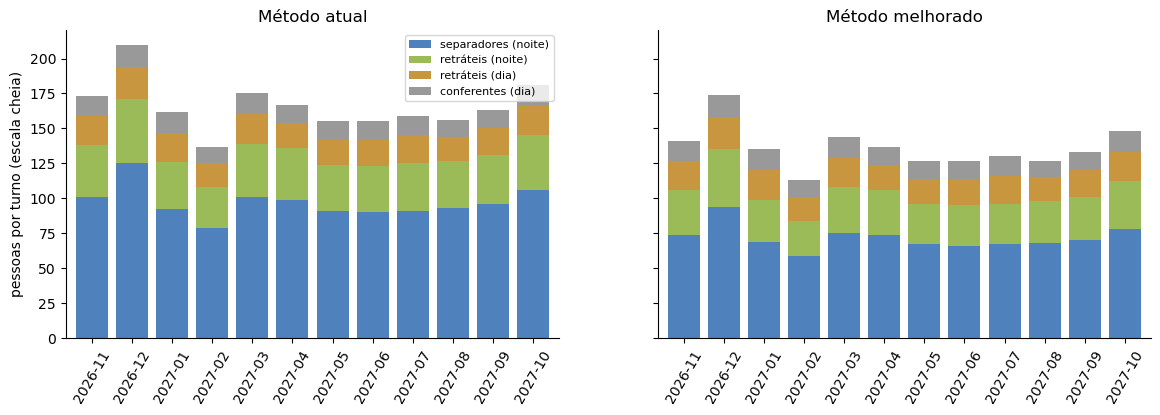

In [6]:
# Barras empilhadas por mês: mostra a composição do quadro (funções) e o pico sazonal.
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
cores = ["#4F81BD", "#9BBB59", "#C8963E", "#999999"]
for ax, (nome, qd) in zip(axes, [("Método atual", q_atual), ("Método melhorado", q_melhor)]):
    qd.plot.bar(stacked=True, ax=ax, color=cores, width=0.8, legend=(ax is axes[0]))
    ax.set_title(nome); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("pessoas por turno (escala cheia)")
axes[0].legend(["separadores (noite)", "retráteis (noite)", "retráteis (dia)", "conferentes (dia)"], fontsize=8)
savefig(fig, "07b_quadro_mensal", out=PH7)

**Leitura:**
- O pico (nov–jan) exige bem mais gente que o resto do ano. Manter **quadro fixo para o pico o ano
  todo** custa muito mais que **fixo + temporários** (comparar as colunas de custo).
- O **método melhorado** (slotting + lote no e-commerce) reduz o quadro em todos os meses, e o ganho
  é maior no pico, quando cada separador a menos também é um temporário a menos para recrutar e treinar.
- Os temporários precisam ser **contratados e treinados em outubro**: no pico não há tempo de curva
  de aprendizado, e a Fase 4 mostrou que os erros de putaway se concentram no turno 2.

In [7]:
economia = custos.loc["atual", "custo_total"] - custos.loc["melhorado", "custo_total"]
print(f"Custo anual de mão de obra direta: atual R$ {custos.loc['atual', 'custo_total']:,.0f} → "
      f"melhorado R$ {custos.loc['melhorado', 'custo_total']:,.0f} (−R$ {economia:,.0f})")
register_saving(7, "Quadro fixo + temporários (vs. fixo dimensionado para o pico)",
                "custo anual de mão de obra direta (R$)", round(custos.loc["atual", "custo_se_tudo_fixo_no_pico"]),
                round(custos.loc["atual", "custo_total"]), "temporários só em nov-jan",
                "labor_cost + temp_premium do config; escala cheia; método atual",
                custos.loc["atual", "custo_se_tudo_fixo_no_pico"] - custos.loc["atual", "custo_total"], 0)
log(NB, f"previsão 12 meses (mês anterior x fator de nível, x{ESCALA}); horas/linha do modelo calibrado; "
        f"pessoas = horas/noite / ({LB['shift_hours']}h x {LB['utilization_target']} x (1-{LB['absenteeism']})); "
        f"fixo = 3º maior mês fora do pico")

Custo anual de mão de obra direta: atual R$ 15,511,997 → melhorado R$ 13,005,245 (−R$ 2,506,752)
